# 15 — Dual-pol observables and eigen-analysis

**Goal:** derive from C2 the basic observables — total power (span), co/cross ratio, the complex
co/cross correlation ρ = C12 / √(C11·C22) — and the eigenvalues λ1 ≥ λ2 of C2.

The two eigenvalues split the power into a dominant, polarized mechanism (λ1) and a residual
depolarized part (λ2). Their balance is what entropy (notebook 16) and DpRVI (notebook 17) measure.
Processing is done **tile by tile** to keep memory low on large AOIs.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from nisar_s1.config import load_kit
from nisar_s1 import product as P

kit = load_kit()                                  # training/notebooks/kit_config.yaml
OUT = Path(kit["data_dir"]) / "outputs" / "15"   # outputs stay outside the repository
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})
import h5py
from nisar_s1 import polarimetry as pol
session = P.load_session(kit["session_file"], required=("gslc_subsets", "c2_looks"))

In [2]:
looks = tuple(session["c2_looks"])
def c2_tiles(path, block=1024):
    """C2 of a GSLC subset, computed tile by tile (block multiple of the looks)."""
    parts = []
    with h5py.File(path) as h5:
        g = P.product_profile(h5).grids["frequencyA"]
        win = P.window_from_bounds(g, g.bounds)
        b = block - block % (looks[0] * looks[1])
        rows = range(win.rows.start, win.rows.stop - looks[0] + 1, b - b % looks[0])
        for i, r0 in enumerate(rows, 1):
            r1 = min(r0 + b - b % looks[0], win.rows.stop)
            w = P.Window(slice(r0, r1), win.cols, g.transform, win.crs)
            parts.append(pol.c2_from_slc(P.read_layer(h5, g, "HH", w), P.read_layer(h5, g, "HV", w), looks))
            print(f"[{i}/{len(rows)}] rows {r0}-{r1}")
    nx = min(p.c11.shape[1] for p in parts)
    cat = lambda k: np.concatenate([getattr(p, k)[:, :nx] for p in parts])
    return pol.C2(cat("c11"), cat("c22"), cat("c12")), win

c2, win = c2_tiles(session["gslc_subsets"][0])
print("C2 shape", c2.c11.shape)

[1/2] rows 0-1024
[2/2] rows 1024-1148
C2 shape (143, 155)


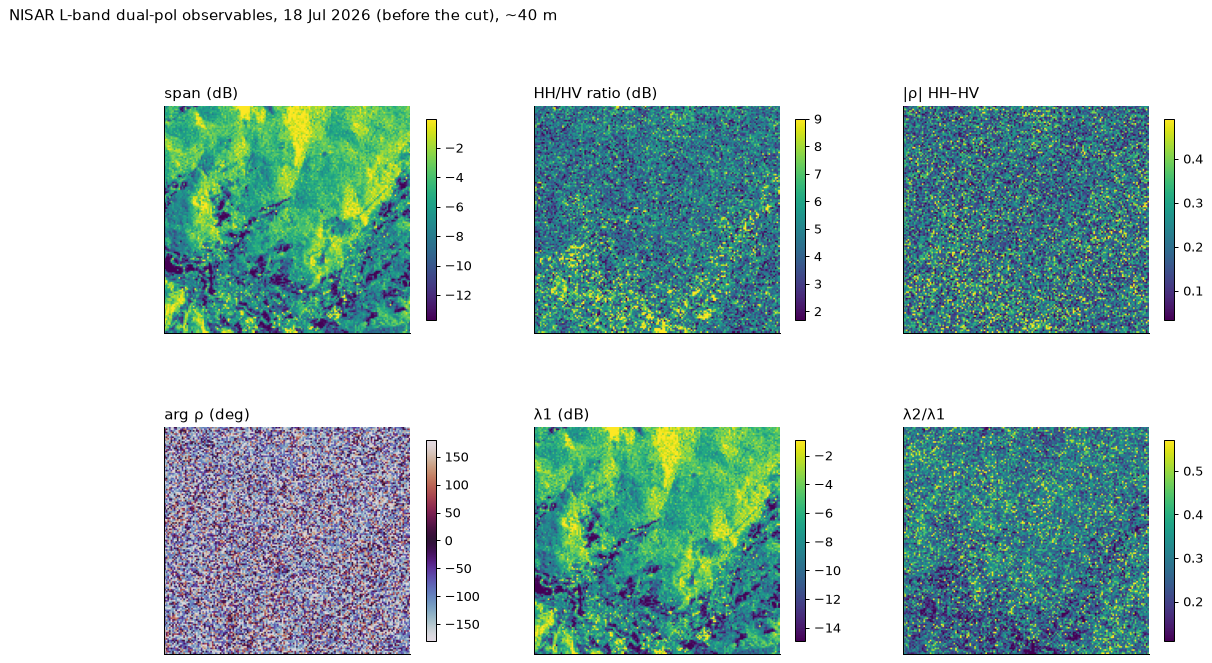

In [3]:
rho = c2.coherence
l1, l2 = pol.eigenvalues(c2)
obs = {"span (dB)": pol.to_db(c2.trace), "HH/HV ratio (dB)": pol.to_db(c2.c11) - pol.to_db(c2.c22),
       "|ρ| HH–HV": np.abs(rho), "arg ρ (deg)": np.degrees(np.angle(rho)),
       "λ1 (dB)": pol.to_db(l1), "λ2/λ1": l2 / l1}
fig, axs = plt.subplots(2, 3, figsize=(15, 8.5))
for ax, (t, a) in zip(axs.ravel(), obs.items()):
    lo, hi = np.nanpercentile(a, [2, 98]) if "arg" not in t else (-180, 180)
    im = ax.imshow(a, cmap="twilight" if "arg" in t else "viridis", vmin=lo, vmax=hi)
    ax.set_title(t, loc="left"); ax.set_xticks([]); ax.set_yticks([]); plt.colorbar(im, ax=ax, shrink=0.75)
fig.suptitle("NISAR L-band dual-pol observables, 18 Jul 2026 (before the cut), ~40 m", x=0.01, ha="left")
fig.savefig(OUT / "15_observables.png", dpi=100, bbox_inches="tight"); plt.show()

**Reading.** Over natural media, |ρ| between HH and HV is **low** (≈ 0.1–0.3): reflection symmetry
makes co- and cross-pol nearly uncorrelated, so most of the information is in the powers. The phase
of ρ is then mostly noise. λ2/λ1 is high where scattering is random (forest volume), low where one
mechanism dominates (bare soil, buildings).

In [4]:
summary = pd.DataFrame({k: pd.Series(v[np.isfinite(v)]).describe(percentiles=[.1, .5, .9]) for k, v in obs.items()}).T
summary.round(3)

,count,mean,std,min,10%,50%,90%,max
span (dB),22165.0,-5.609,3.259,-16.393,-10.193,-5.149,-1.942,12.945
HH/HV ratio (dB),22165.0,4.898,1.765,-3.405,2.889,4.783,6.950,22.546
|ρ| HH–HV,22165.0,0.224,0.116,0.001,0.083,0.213,0.377,0.927
arg ρ (deg),22165.0,-37.081,109.244,-179.988,-155.938,-74.464,145.459,180.000
λ1 (dB),22165.0,-6.749,3.332,-18.695,-11.344,-6.336,-2.973,12.937
λ2/λ1,22165.0,0.305,0.109,0.002,0.178,0.293,0.447,0.904


In [5]:
checks = {
    "|ρ| within [0, 1]": np.nanmax(np.abs(rho)) <= 1 + 1e-5,
    "λ1 >= λ2": np.all((l1 >= l2)[np.isfinite(l1)]),
    "low median |ρ| (reflection symmetry)": np.nanmedian(np.abs(rho)) < 0.5,
}
for k, v in checks.items():
    print(f"  [{'x' if v else ' '}] {k}")
assert all(checks.values()), "some checks failed: read the messages above"
print("Module 15 STATUS: PASS")

  [x] |ρ| within [0, 1]
  [x] λ1 >= λ2
  [x] low median |ρ| (reflection symmetry)
Module 15 STATUS: PASS
